In [11]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

from interpmodules import helpers

Loaded aesthetics module


In [1]:
# This code block tests Variography with GSTOOLS
import gstools as gs

In [2]:
mdl = gs.CovModel

In [ ]:
import numpy as np
# starting point for parameter values

def init_parameters(mapvals, Dist, h, ev):

    nh = len(h)
    p0 = {
          3: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh],
          4: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh, ev[0]]
         }
    # upper bound lower bound
    bounds = {3: ([0.00001]*3, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals))]),
    4: ([0.00001]*4, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals)), 100])}

    return p0, bounds

In [9]:
import numpy as np

import gstools as gs

mdl = gs.covmodel.Gaussian()

# Exemplary variogram data (e.g. estimated from field observations)
h = np.array([1.0, 3.0, 5.0, 7.0, 9.0, 11.0])
ev = np.array([0.2, 0.5, 0.6, 0.8, 0.8, 0.9])
nh = h.shape[0]

# fitting model
model = mdl
# we have to provide boundaries for the parameters

bounds = {"len_scale": [0.00001, np.max(h)], \
      "var": [0.0001, np.nanmax(ev)], \
      "nugget": [0.0001, np.nanmax(ev)/nh]
     }

model.set_arg_bounds(**bounds)

results, pcov = model.fit_variogram(h, ev)
print("Results:", results)



Results: {'var': np.float64(0.6966403137693233), 'len_scale': np.float64(3.80153339688048), 'nugget': np.float64(0.14999999999999997)}


/home/yzhou/anaconda3/envs/py311/lib/python3.11/site-packages/gstools/covmodel/plot.py:134: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: >

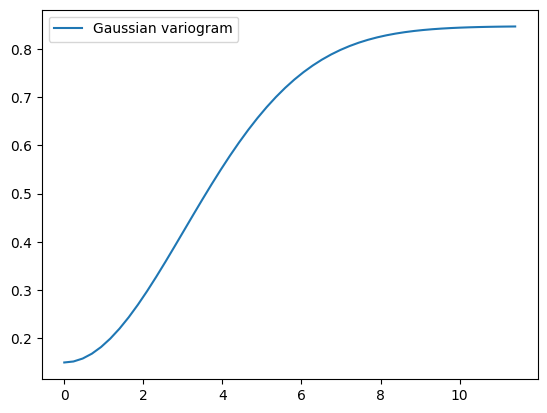

In [10]:
model.plot()

# Variography with SKGSTAT AND RUDIMENTARY FUNCTION DEFINITION

In [13]:
# Models

from interpmodules import helpers
import skgstat as skg
skgstat_mdls = {'spherical': skg.models.spherical, 
                'exponential': skg.models.exponential,
                'gaussian': skg.models.gaussian,
                'cubic': skg.models.cubic,
                'stable': skg.models.stable,
                'matern': skg.models.matern,
               'hole': helpers.hole}

In [14]:
# set up data
import joblib
import pandas as pd

src_pvdata = joblib.load( projdir + '/data/fsLR-4k_reduced-midthickness_neuromaps.pkl')

maptags = pd.read_table(projdir + '/data/surf_map_names', delimiter = " ", dtype = str)
maptags = list(maptags.columns)


In [15]:
Dist = helpers.internal_distance_matrix(src_pvdata.points, 'euclidean')

In [16]:
import joblib
mapnames, h, all_ev = joblib.load( '/home/yzhou/gitrepo/interpolate/results/stats/neuromaps_collected_expvgm.pkl' )

In [17]:
import numpy as np
# starting point for parameter values

def init_parameters(mapvals, Dist, h, ev):

    nh = len(h)
    p0 = {
          3: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh],
          4: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh, ev[0]]
         }
    # upper bound lower bound
    bounds = {3: ([0.00001]*3, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals))]),
    4: ([0.00001]*4, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals)), 100])}

    return p0, bounds

In [18]:
def semivariance(y1, y2):
    return .5 * (y1 - y2)**2

In [19]:
model_scores = {}


In [124]:
mapnames

['abagen_genepc1',
 'hcps1200_megbeta',
 'hcps1200_meggamma2',
 'hcps1200_meggamma1',
 'hcps1200_megtimescale',
 'hcps1200_megtheta',
 'hcps1200_megalpha',
 'hcps1200_megdelta',
 'hcps1200_thickness',
 'hcps1200_myelinmap',
 'xu2020_FChomology',
 'mueller2013_intersubjvar',
 'margulies2016_fcgradient01',
 'sydnor2021_SAaxis',
 'raichle_cbv',
 'raichle_cbf',
 'raichle_cmrglc',
 'raichle_cmr02',
 'reardon2018_scalinghcp',
 'xu2020_evoexp',
 'hill2010_devexp',
 'reardon2018_scalingnih',
 'reardon2018_scalingpnc',
 'hill2010_evoexp']

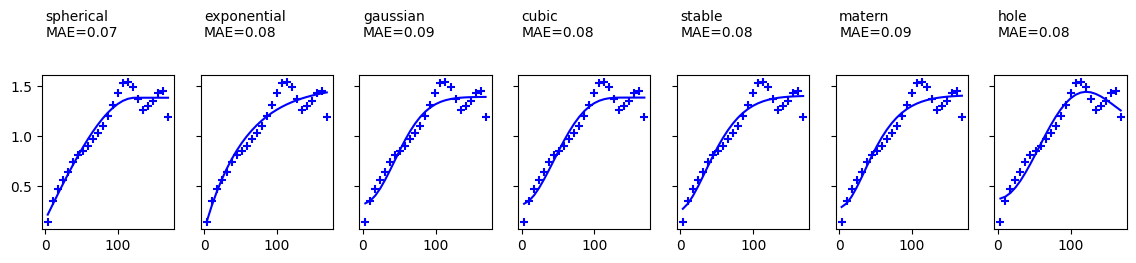

In [129]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from interpmodules import metrics
from scipy.stats import zscore

# Fitting
mi=8
mapname=mapnames[mi]
mapvals = src_pvdata[mapname]

Cof = {}
Cov = {}
gof = {}

fig, axs = plt.subplots(1, len(skgstat_mdls), figsize = (14,2), sharey=True)

ev = all_ev[:,mi]


for ind, model in enumerate(skgstat_mdls):

    

    p0, bounds = init_parameters(mapvals, Dist, h, ev)
    
    axs[ind].scatter(h, ev, marker = "+", color = 'b')

    cof = None; cov = None
    
    if model in ['stable', 'matern']:
        cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = p0[4], bounds = bounds[4], maxfev=1000)
    
    else:
        cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = p0[3], bounds = bounds[3], maxfev=1000)

    Cof[model] = cof
    Cov[model] = cov
    
    v_pred = skgstat_mdls[model](h, *cof)
    x_s = np.linspace(h.min(), h.max())
    axs[ind].plot(h, v_pred, color = 'b')
    mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
    r2 = r2_score(ev, v_pred, force_finite=False)
    gof[model] = r2
    
    axs[ind].text(x=0, y=2,s= model + "\n" + r'MAE=' + '{0:.2f}'.format(mae))

model_scores[mapname] = gof

# Same thing, with GSTools

In [130]:
gstools_mdls = {'spherical': gs.covmodel.Spherical, 
                'exponential': gs.covmodel.Exponential,
                'gaussian': gs.covmodel.Gaussian,
                'cubic': gs.covmodel.Cubic,
                'stable': gs.covmodel.Stable,
                'matern': gs.covmodel.Matern,
               'hole': gs.covmodel.JBessel}

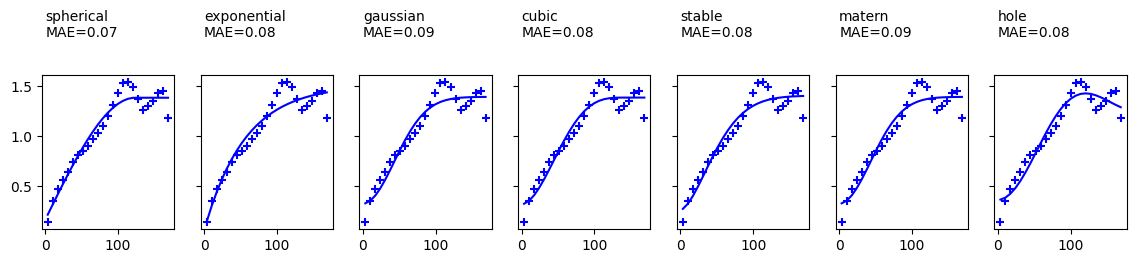

In [131]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from interpmodules import metrics
from scipy.stats import zscore

# Fitting
mapname=mapnames[mi]
mapvals = src_pvdata[mapname]

Cof = {}
Cov = {}
gof = {}

fig, axs = plt.subplots(1, len(skgstat_mdls), figsize = (14,2), sharey=True)

ev = all_ev[:,mi]

for ind, model in enumerate(gstools_mdls):

    cof = None; cov = None

    axs[ind].scatter(h, ev, marker = "+", color = 'b')
    
    p0, bounds = init_parameters(mapvals, Dist, h, ev)

    mdl = gstools_mdls[model](dim=3)
    
    if model in ['stable', 'matern']:
            
        in_bounds = {"len_scale": [bounds[4][0][0], bounds[4][1][0]],\
                 "var": [bounds[4][0][1], bounds[4][1][1]],\
                 "nugget": [bounds[4][0][2], bounds[4][1][2]],\
                 "smoothness": [bounds[4][0][3], bounds[4][1][3]]
                }

        if model == 'stable':
            in_bounds["alpha"] = in_bounds.pop("smoothness")
            
        if model == 'matern':
            in_bounds["nu"] = in_bounds.pop("smoothness")

        
        mdl.set_arg_bounds(**in_bounds)
        
        cof, cov = mdl.fit_variogram(h,ev)
    
    else:
        in_bounds = {"len_scale": [bounds[3][0][0], bounds[3][1][0]],\
                 "var": [bounds[3][0][1], bounds[3][1][1]],\
                 "nugget": [bounds[3][0][2], bounds[3][1][2]]
                }
        
        mdl.set_arg_bounds(**in_bounds)
        cof, cov = mdl.fit_variogram(h,ev)

    Cof[model] = cof
    Cov[model] = cov
    
    v_pred = mdl.variogram(h)
    x_s = np.linspace(h.min(), h.max())
    axs[ind].plot(h, v_pred, color = 'b')
    mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
    r2 = r2_score(ev, v_pred, force_finite=False)
    gof[model] = r2
    
    axs[ind].text(x=0, y=2,s= model + "\n" + r'MAE=' + '{0:.2f}'.format(mae))

model_scores[mapname] = gof

In [132]:
best_model_name = pd.DataFrame(model_scores).sort_values(by=mapname).index[-1]

In [133]:
best_model_name

'spherical'

In [134]:
Cof[best_model_name]

{'var': np.float64(1.2264431613413584),
 'len_scale': np.float64(123.16620841215398),
 'nugget': np.float64(0.1604239230511771)}

# Try Kriging directly with a gstools variogram

In [135]:
import joblib

kc,kv,uc, uv = joblib.load(projdir + "/data/sampling/fsLR-4k_reduced-midthickness_samp-dsk33_pct-25_iters-100.pkl")[1]

X0=kc[:,:,0]
Y0 = mapvals[kv[:,0].astype(int)]
x1=uc[:,:,0]

In [136]:
uc.shape

(2700, 3, 100)

In [137]:
h, ev, N = helpers.get_empirical_variogram_fast(x=Y0,X=X0,D=Dist,nh=25,h_bounds='auto', method='euclidean')

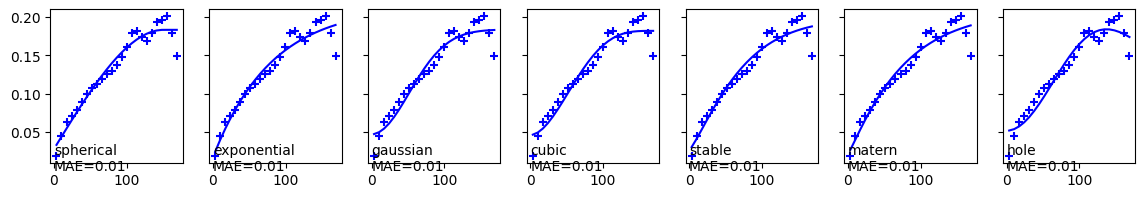

In [139]:
fig, axs = plt.subplots(1, len(skgstat_mdls), figsize = (14,2), sharey=True)


for ind, model in enumerate(gstools_mdls):

    cof = None; cov = None

    axs[ind].scatter(h, ev, marker = "+", color = 'b')
    
    p0, bounds = init_parameters(mapvals, Dist, h, ev)

    mdl = gstools_mdls[model](dim=3)
    
    if model in ['stable', 'matern']:
            
        in_bounds = {"len_scale": [bounds[4][0][0], bounds[4][1][0]],\
                 "var": [bounds[4][0][1], bounds[4][1][1]],\
                 "nugget": [bounds[4][0][2], bounds[4][1][2]],\
                 "smoothness": [bounds[4][0][3], bounds[4][1][3]]
                }

        if model == 'stable':
            in_bounds["alpha"] = [bounds[4][0][3], 2]
            del in_bounds["smoothness"]
            
        if model == 'matern':
            in_bounds["nu"] = [bounds[4][0][3], 30]
            del in_bounds["smoothness"]

        
        mdl.set_arg_bounds(**in_bounds)
        
        cof, cov = mdl.fit_variogram(h,ev)
    
    else:
        in_bounds = {"len_scale": [bounds[3][0][0], bounds[3][1][0]],\
                 "var": [bounds[3][0][1], bounds[3][1][1]],\
                 "nugget": [bounds[3][0][2], bounds[3][1][2]]
                }
        
        mdl.set_arg_bounds(**in_bounds)
        cof, cov = mdl.fit_variogram(h,ev)

    Cof[model] = cof
    Cov[model] = cov
    
    v_pred = mdl.variogram(h)
    x_s = np.linspace(h.min(), h.max())
    axs[ind].plot(h, v_pred, color = 'b')
    mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
    r2 = r2_score(ev, v_pred, force_finite=False)
    gof[model] = r2
    
    axs[ind].text(x=0, y=0,s= model + "\n" + r'MAE=' + '{0:.2f}'.format(mae))

model_scores[mapname] = gof

In [140]:
Cof['hole']

{'var': np.float64(0.10853434468475547),
 'len_scale': np.float64(30.5143104580779),
 'nugget': np.float64(0.05184821248588587),
 'nu': np.float64(0.5000000000000001)}

In [141]:
model_scores

{'abagen_genepc1': {'spherical': 0.7343550765808446,
  'exponential': 0.7651462861140828,
  'gaussian': 0.9861936621230518,
  'cubic': 0.7133362728132566,
  'stable': 0.9955946489561546,
  'matern': 0.9933632397985778,
  'hole': 0.9959133477257478},
 'hcps1200_thickness': {'spherical': 0.9546500560627587,
  'exponential': 0.9444853865886443,
  'gaussian': 0.9360231726881781,
  'cubic': 0.939368193213543,
  'stable': 0.9454712520955754,
  'matern': 0.9446495012933962,
  'hole': 0.9389217277426434}}

In [142]:
best_model_name = pd.DataFrame(model_scores).sort_values(by=mapname).index[-1]

In [143]:
Cof

{'spherical': {'var': np.float64(0.15514477194969148),
  'len_scale': np.float64(150.1974106203492),
  'nugget': np.float64(0.028049566755977064)},
 'exponential': {'var': np.float64(0.1972787448515049),
  'len_scale': np.float64(80.41165638101877),
  'nugget': np.float64(0.0164652067636624)},
 'gaussian': {'var': np.float64(0.13647232552652314),
  'len_scale': np.float64(64.63692504391918),
  'nugget': np.float64(0.04717838289158316)},
 'cubic': {'var': np.float64(0.13550502820446209),
  'len_scale': np.float64(172.16221730373388),
  'nugget': np.float64(0.04635380190894965)},
 'stable': {'var': np.float64(0.1719428601581185),
  'len_scale': np.float64(73.60325530694305),
  'nugget': np.float64(0.026513361047462557),
  'alpha': np.float64(1.2272745248543693)},
 'matern': {'var': np.float64(0.18712455149670526),
  'len_scale': np.float64(52.97068475004256),
  'nugget': np.float64(0.021501830170902857),
  'nu': np.float64(0.5883300842369542)},
 'hole': {'var': np.float64(0.1085343446847

In [144]:
from pykrige.ok3d import OrdinaryKriging3D

preds = dict.fromkeys(gstools_mdls.keys())

for ind, model in enumerate(gstools_mdls):
    fitted_vario = gstools_mdls[model](dim=3, **Cof[model])

    kriger = OrdinaryKriging3D(x=X0[:,0], y=X0[:,1], z=X0[:,2], val = Y0,\
                                   variogram_model = fitted_vario, \
                                exact_values = True)
    y1, error = kriger.execute(style = 'points', xpoints = x1[:,0], ypoints = x1[:,1], zpoints = x1[:, 2])

    full_map = np.zeros(src_pvdata.n_points)
    full_map[kv[:,0].astype(int)] = mapvals[kv[:,0].astype(int)]
    full_map[uv[:,0].astype(int)] = y1

    preds[model] = full_map
    print("done model: " + model + " with coefficients " + str(Cof[model]))

done model: spherical with coefficients {'var': np.float64(0.15514477194969148), 'len_scale': np.float64(150.1974106203492), 'nugget': np.float64(0.028049566755977064)}
done model: exponential with coefficients {'var': np.float64(0.1972787448515049), 'len_scale': np.float64(80.41165638101877), 'nugget': np.float64(0.0164652067636624)}
done model: gaussian with coefficients {'var': np.float64(0.13647232552652314), 'len_scale': np.float64(64.63692504391918), 'nugget': np.float64(0.04717838289158316)}
done model: cubic with coefficients {'var': np.float64(0.13550502820446209), 'len_scale': np.float64(172.16221730373388), 'nugget': np.float64(0.04635380190894965)}
done model: stable with coefficients {'var': np.float64(0.1719428601581185), 'len_scale': np.float64(73.60325530694305), 'nugget': np.float64(0.026513361047462557), 'alpha': np.float64(1.2272745248543693)}
done model: matern with coefficients {'var': np.float64(0.18712455149670526), 'len_scale': np.float64(52.97068475004256), 'nu

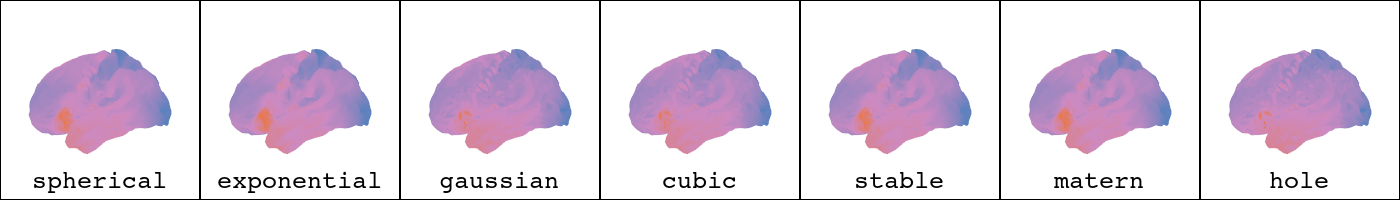

In [145]:
import pyvista as pv

pl = pv.Plotter(shape = (1,7), window_size = (1400, 200))

for ind, model in enumerate(gstools_mdls):

    pl.subplot(0,ind)
    pl.add_mesh(src_pvdata.rotate_z(180), scalars=preds[model], cmap = bpr, **mesh_aes)
    pl.add_text(model, position="lower_edge", font = 'courier', font_size = 10)
    pl.camera_position='yz'
    
pl.show(jupyter_backend='static')

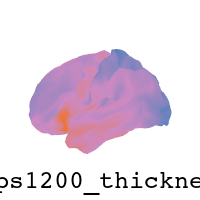

In [146]:
import pyvista as pv

pl = pv.Plotter(window_size = (200, 200))

pl.add_mesh(src_pvdata.rotate_z(180), scalars=mapname, cmap = bpr, **mesh_aes)
pl.add_text(mapname, position="lower_edge", font = 'courier', font_size = 10)
pl.camera_position='yz'
    
pl.show(jupyter_backend='static')

In [147]:
from interpmodules import metrics

In [149]:
# also spin it
for model in gstools_mdls:
    print(model)
    y_true = mapvals[uv[:,0].astype(int)]
    y_pred = preds[model][uv[:,0].astype(int)]
    error = metrics.metric(actual=y_true, interpolated=y_pred, method="rmse")
    nrmse = error/np.std(y_true)
    print(nrmse)

spherical
0.46200448
exponential
0.42731616
gaussian
0.6195377
cubic
0.5807805
stable
0.4590388
matern
0.4411116
hole
0.66355777


# do it 100 times

In [154]:
model_scores = {}

In [209]:
def get_best_variogram_model(X0, Y0, D, nh, candidate_models, plot=True):
    
    h, ev, N = helpers.get_empirical_variogram_fast(x=Y0,X=X0,D=Dist,nh=25,h_bounds='auto', method='euclidean')

    if plot: 
        fig, axs = plt.subplots(1, len(candidate_models), figsize = (2*len(candidate_models),2), sharey=True)

    for ind, model in enumerate(candidate_models):
    
        cof = None; cov = None
        
        p0, bounds = init_parameters(Y0, Dist, h, ev)
    
        mdl = candidate_models[model](dim=3)

        try:
            if model in ['stable', 'matern']:
                    
                in_bounds = {"len_scale": [bounds[4][0][0], bounds[4][1][0]],\
                         "var": [bounds[4][0][1], bounds[4][1][1]],\
                         "nugget": [bounds[4][0][2], bounds[4][1][2]],\
                         "smoothness": [bounds[4][0][3], bounds[4][1][3]]
                        }
        
                if model == 'stable':
                    in_bounds["alpha"] = [bounds[4][0][3], 2]
                    del in_bounds["smoothness"]
    
                    cof, cov = mdl.fit_variogram(h,ev, init_guess = {"len_scale": p0[4][0], "var": p0[4][1], "nugget": p0[4][2], "alpha": p0[4][3]}, 
                                             max_eval = 1000)
                    
                if model == 'matern':
                    in_bounds["nu"] = [bounds[4][0][3], 30]
                    del in_bounds["smoothness"]
    
                    cof, cov = mdl.fit_variogram(h,ev, init_guess = {"len_scale": p0[4][0], "var": p0[4][1], "nugget": p0[4][2], "nu": p0[4][3]}, 
                                             max_eval = 1000)
        
                
                mdl.set_arg_bounds(**in_bounds)
                
                        
            else:
                in_bounds = {"len_scale": [bounds[3][0][0], bounds[3][1][0]],\
                         "var": [bounds[3][0][1], bounds[3][1][1]],\
                         "nugget": [bounds[3][0][2], bounds[3][1][2]]
                        }
                
                mdl.set_arg_bounds(**in_bounds)
            
                cof, cov = mdl.fit_variogram(h,ev, init_guess = {"len_scale": p0[3][0], "var": p0[3][1], "nugget": p0[3][2]}, 
                                         max_eval = 1000)
        except:
            Cof[model] = None
            Cov[model] = None
            continue
    
        Cof[model] = cof
        Cov[model] = cov
        
        v_pred = mdl.variogram(h)
        x_s = np.linspace(h.min(), h.max())
        
        mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
        r2 = r2_score(ev, v_pred, force_finite=False)
        gof[model] = r2

        if plot:
            axs[ind].plot(h, v_pred, color = 'b')
            axs[ind].scatter(h, ev, marker = "+", color = 'b')
            axs[ind].text(x=0, y=np.nanmax(ev)*0.8,s= model + "\n" + r'MAE=' + '{0:.2f}'.format(mae))
    
    model_scores[mapname] = gof
    
    return model_scores

In [206]:
extended_cpal = {}

from interpmodules import helpers

global_i_s = pd.DataFrame(index = maptags, columns = ['i'])

Dist = helpers.internal_distance_matrix(src_pvdata.points, 'geodesic')

for maptag in maptags:
    global_i = helpers.morans_i(Dist, src_pvdata[maptag], normalize=True)
    global_i_s.loc[maptag] = global_i

cat = []

maptocat = {'gene expression': ['abagen_genepc1'], \
            'MEG': ['hcps1200_meg' + fband for fband in fbands ] + ['hcps1200_megtimescale'], \
            'structural': ['hcps1200_thickness', 'hcps1200_myelinmap'], \
            'functional': ['margulies2016_fcgradient01', 'mueller2013_intersubjvar', 'xu2020_FChomology', 'sydnor2021_SAaxis'], \
            'metabolism': ['raichle_cbf', 'raichle_cbv', 'raichle_cmr02', 'raichle_cmrglc'], \
            'expansion': ['hill2010_devexp', 'hill2010_evoexp', 'xu2020_evoexp', 'reardon2018_scalinghcp', 'reardon2018_scalingnih', 'reardon2018_scalingpnc']}


for row in range(len(global_i_s)):
    for category in maptocat:
        if global_i_s.index[row] in maptocat[category]:
            cat.append( category )
        else: continue

global_i_s['category'] = cat


for maptag in mapnames:
    extended_cpal[maptag] = cpal[global_i_s.loc[maptag]['category']]

In [243]:
import joblib

kc,kv,uc, uv = joblib.load(projdir + "/data/sampling/fsLR-4k_reduced-midthickness_samp-dsk33_pct-5_iters-100.pkl")[1]

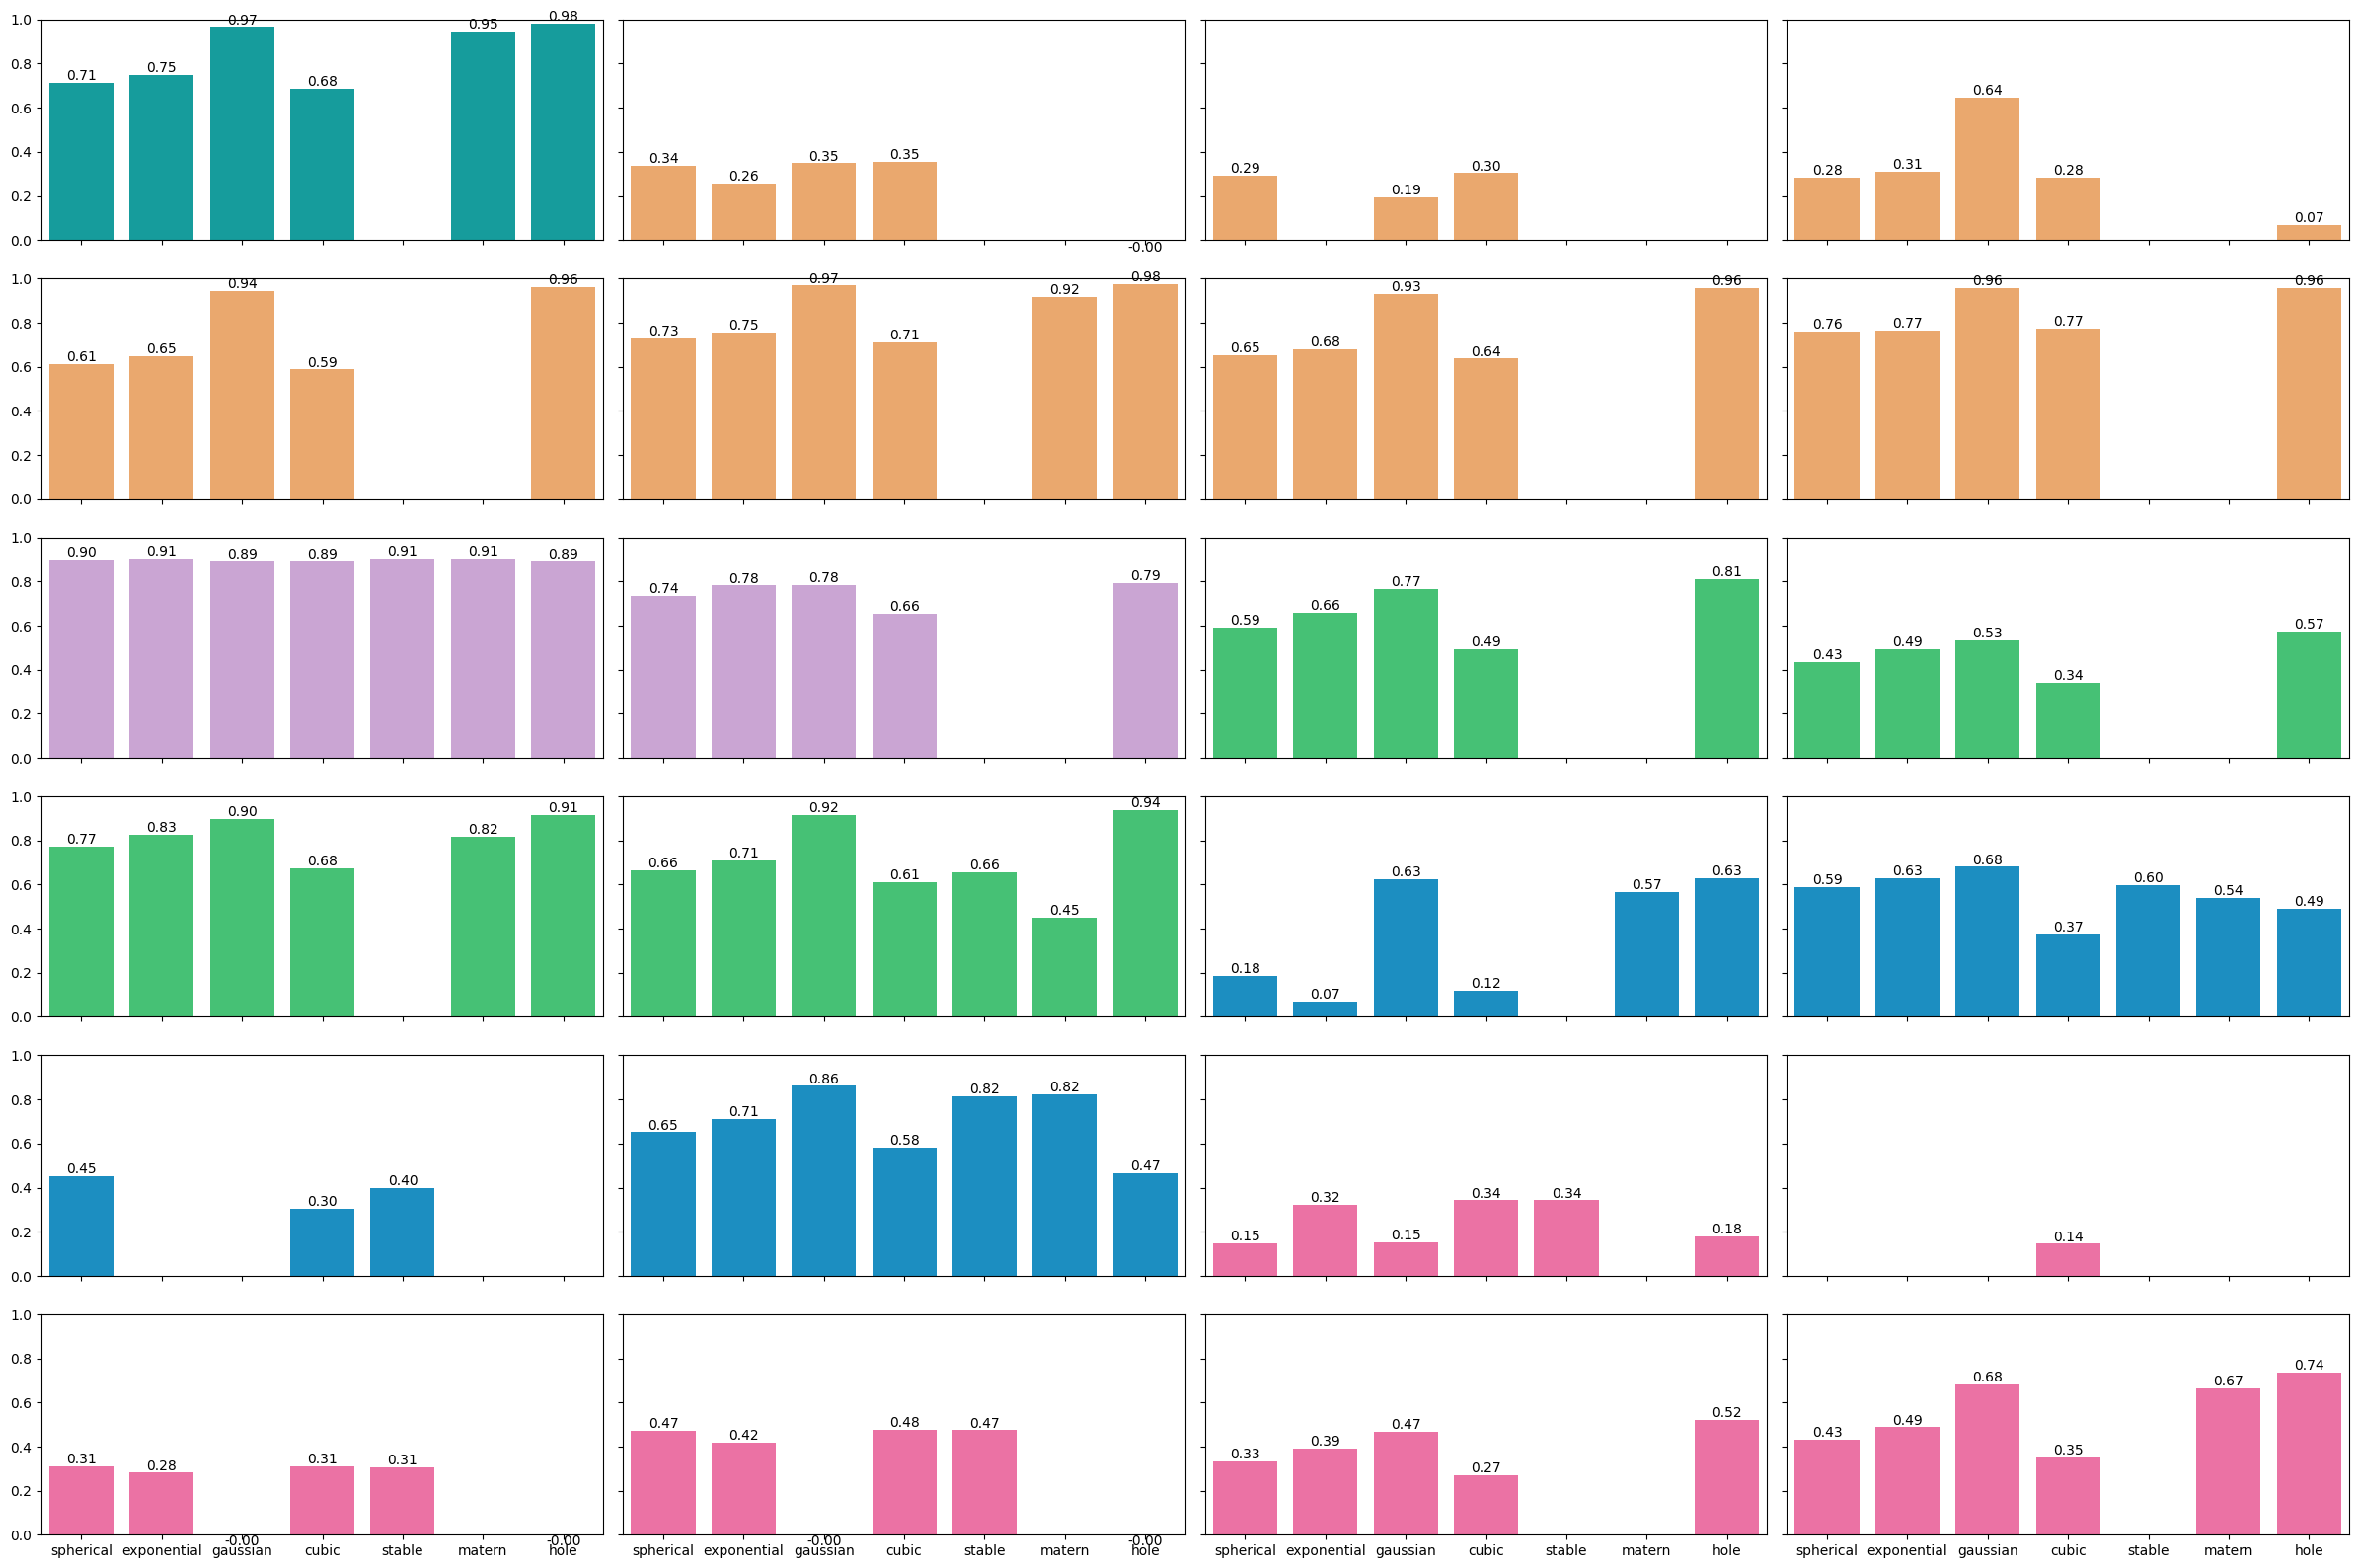

In [244]:
import seaborn as sns
import pandas as pd
fig, axs = plt.subplots(6, 4, figsize = (24, 16), sharey=True, sharex=True)

for mi, mapname in enumerate(mapnames):
    mapname=mapnames[mi]
    mapvals = src_pvdata[mapname]

    scores = pd.DataFrame(
        [get_best_variogram_model(X0=kc[:,:,i], Y0=mapvals[kv[:,i].astype(int)], D=Dist, nh=25, candidate_models=gstools_mdls, plot=False)[mapname] for i in range(100)], 
        columns = gstools_mdls.keys())

    row = mi // 4 ; col = mi % 4
    sns.barplot(scores, errorbar='se', color = extended_cpal[mapname], ax=axs[row, col])
    axs[row, col].bar_label(axs[row, col].containers[0], fmt='%.2f', fontsize=10)
    axs[row,col].set_ylim([0,1])
plt.tight_layout()
plt.savefig(projdir + '/figs/rev_variogram_fit_5pct.svg')

# Interpolate

In [299]:
import joblib
from pykrige.ok3d import OrdinaryKriging3D
from scipy.stats import zscore

for percent in [5, 10, 25, 50]:
    kc,kv,uc, uv = joblib.load(projdir + f"/data/sampling/fsLR-4k_reduced-midthickness_samp-dsk33_pct-{str(percent)}_iters-100.pkl")[1]

    X0=kc[:,:,0]
    x1=uc[:,:,0]
    
    Scores = {}
    Preds = {}
    
    for mi, mapname in enumerate(mapnames):
        mapvals = zscore(src_pvdata[mapname])
        Y0 = mapvals[kv[:,0].astype(int)]
    
        Nrmse = {}
    
        preds = dict.fromkeys(gstools_mdls.keys())
        
        for ind, model in enumerate(gstools_mdls):
            fitted_vario = gstools_mdls[model](dim=3, **Cof[model])
        
            kriger = OrdinaryKriging3D(x=X0[:,0], y=X0[:,1], z=X0[:,2], val = Y0,\
                                           variogram_model = fitted_vario, \
                                        exact_values = True)
            y1, error = kriger.execute(style = 'points', xpoints = x1[:,0], ypoints = x1[:,1], zpoints = x1[:, 2])
        
            full_map = np.zeros(src_pvdata.n_points)
            full_map[kv[:,0].astype(int)] = mapvals[kv[:,0].astype(int)]
            full_map[uv[:,0].astype(int)] = y1
        
            preds[model] = full_map
            
            #print(model)
            y_true = mapvals[uv[:,0].astype(int)]
            y_pred = preds[model][uv[:,0].astype(int)]
            error = metrics.metric(actual=y_true, interpolated=y_pred, method="rmse")
            nrmse = error/np.std(y_true)
            #print(nrmse)
            Nrmse[model] = nrmse
    
        Preds[mapname] = preds
        Scores[mapname] = Nrmse

        joblib.dump((("preds", "scores"), Preds, Scores), projdir + f'/results/rev_ok_other_models_pct-{str(percent)}.pkl')

In [398]:
import joblib


interpolations = joblib.load(projdir + "/results/rev_ok_other_models_pct-10.pkl")

In [399]:
tags, results, error = interpolations

In [400]:
import joblib

kc,kv,uc, uv = joblib.load(projdir + "/data/sampling/fsLR-4k_reduced-midthickness_samp-dsk33_pct-10_iters-100.pkl")[1]

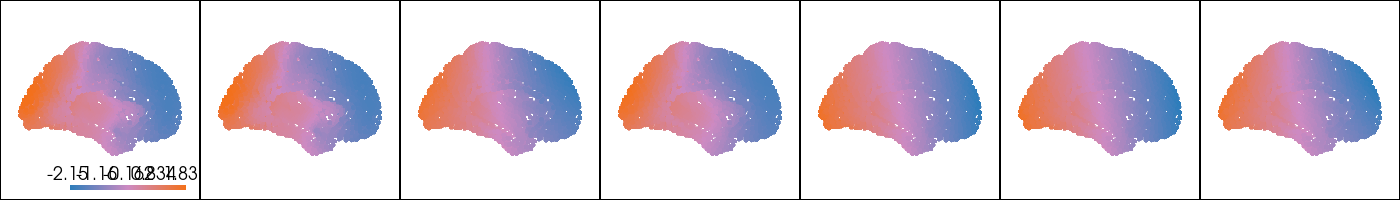

In [401]:
import pyvista as pv

pl = pv.Plotter(shape = (1, len(gstools_mdls)), window_size = (1400, 200))

mapname = 'hcps1200_megalpha'

for ind, model in enumerate(gstools_mdls.keys()):

    pl.subplot(0, ind)
    pl.add_points(pv.PolyData(uc[:,:,0]), scalars = results[mapname][model][uv[:,0].astype(int)], 
                            cmap = bpr, **point_aes)
    pl.camera_position = 'yz'

pl.show(jupyter_backend='static')

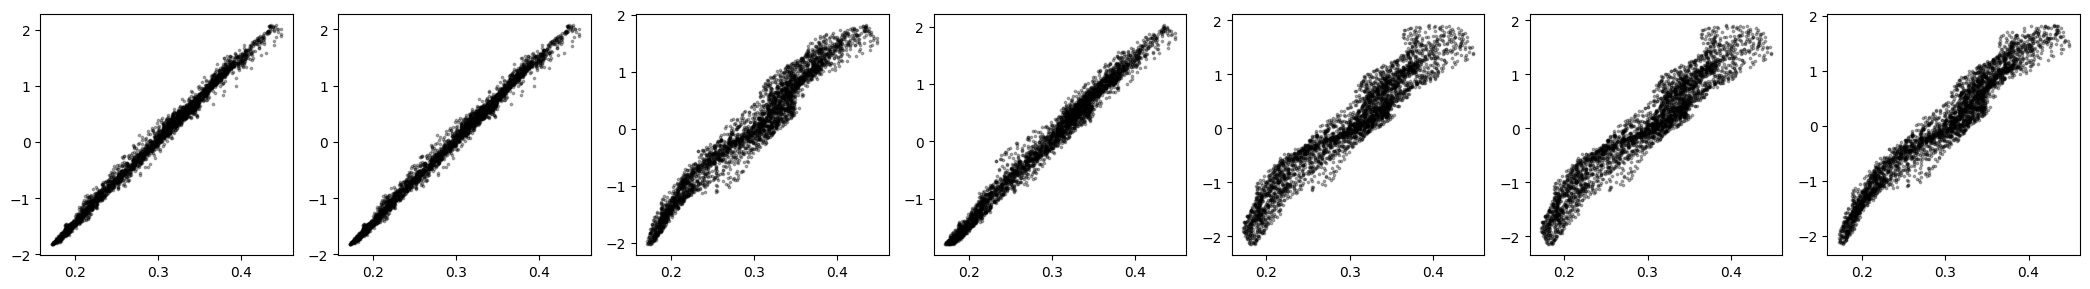

In [402]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1,len(gstools_mdls), figsize = (21,3))

for ind, model in enumerate(gstools_mdls.keys()):
    axs[ind].scatter( y=results[mapname][model][uv[:,0].astype(int)], 
             x=src_pvdata[mapname][uv[:,0].astype(int)],
             c='k', s=3, alpha=.3)
plt.tight_layout()
plt.show()

In [403]:
from sklearn.metrics import root_mean_squared_error

for model in gstools_mdls.keys():
    print(model)
    
    y_true = src_pvdata[mapname][uv[:,0].astype(int)]
    y_pred = results[mapname][model][uv[:,0].astype(int)]
    
    print(root_mean_squared_error(y_true, y_pred))
    print(np.std(y_true))

spherical
0.9673586778449516
0.06734865
exponential
0.9672151840329957
0.06734865
gaussian
0.9510709750406475
0.06734865
cubic
0.9558488998064876
0.06734865
stable
0.937655425279897
0.06734865
matern
0.937655433756763
0.06734865
hole
0.948621977379069
0.06734865


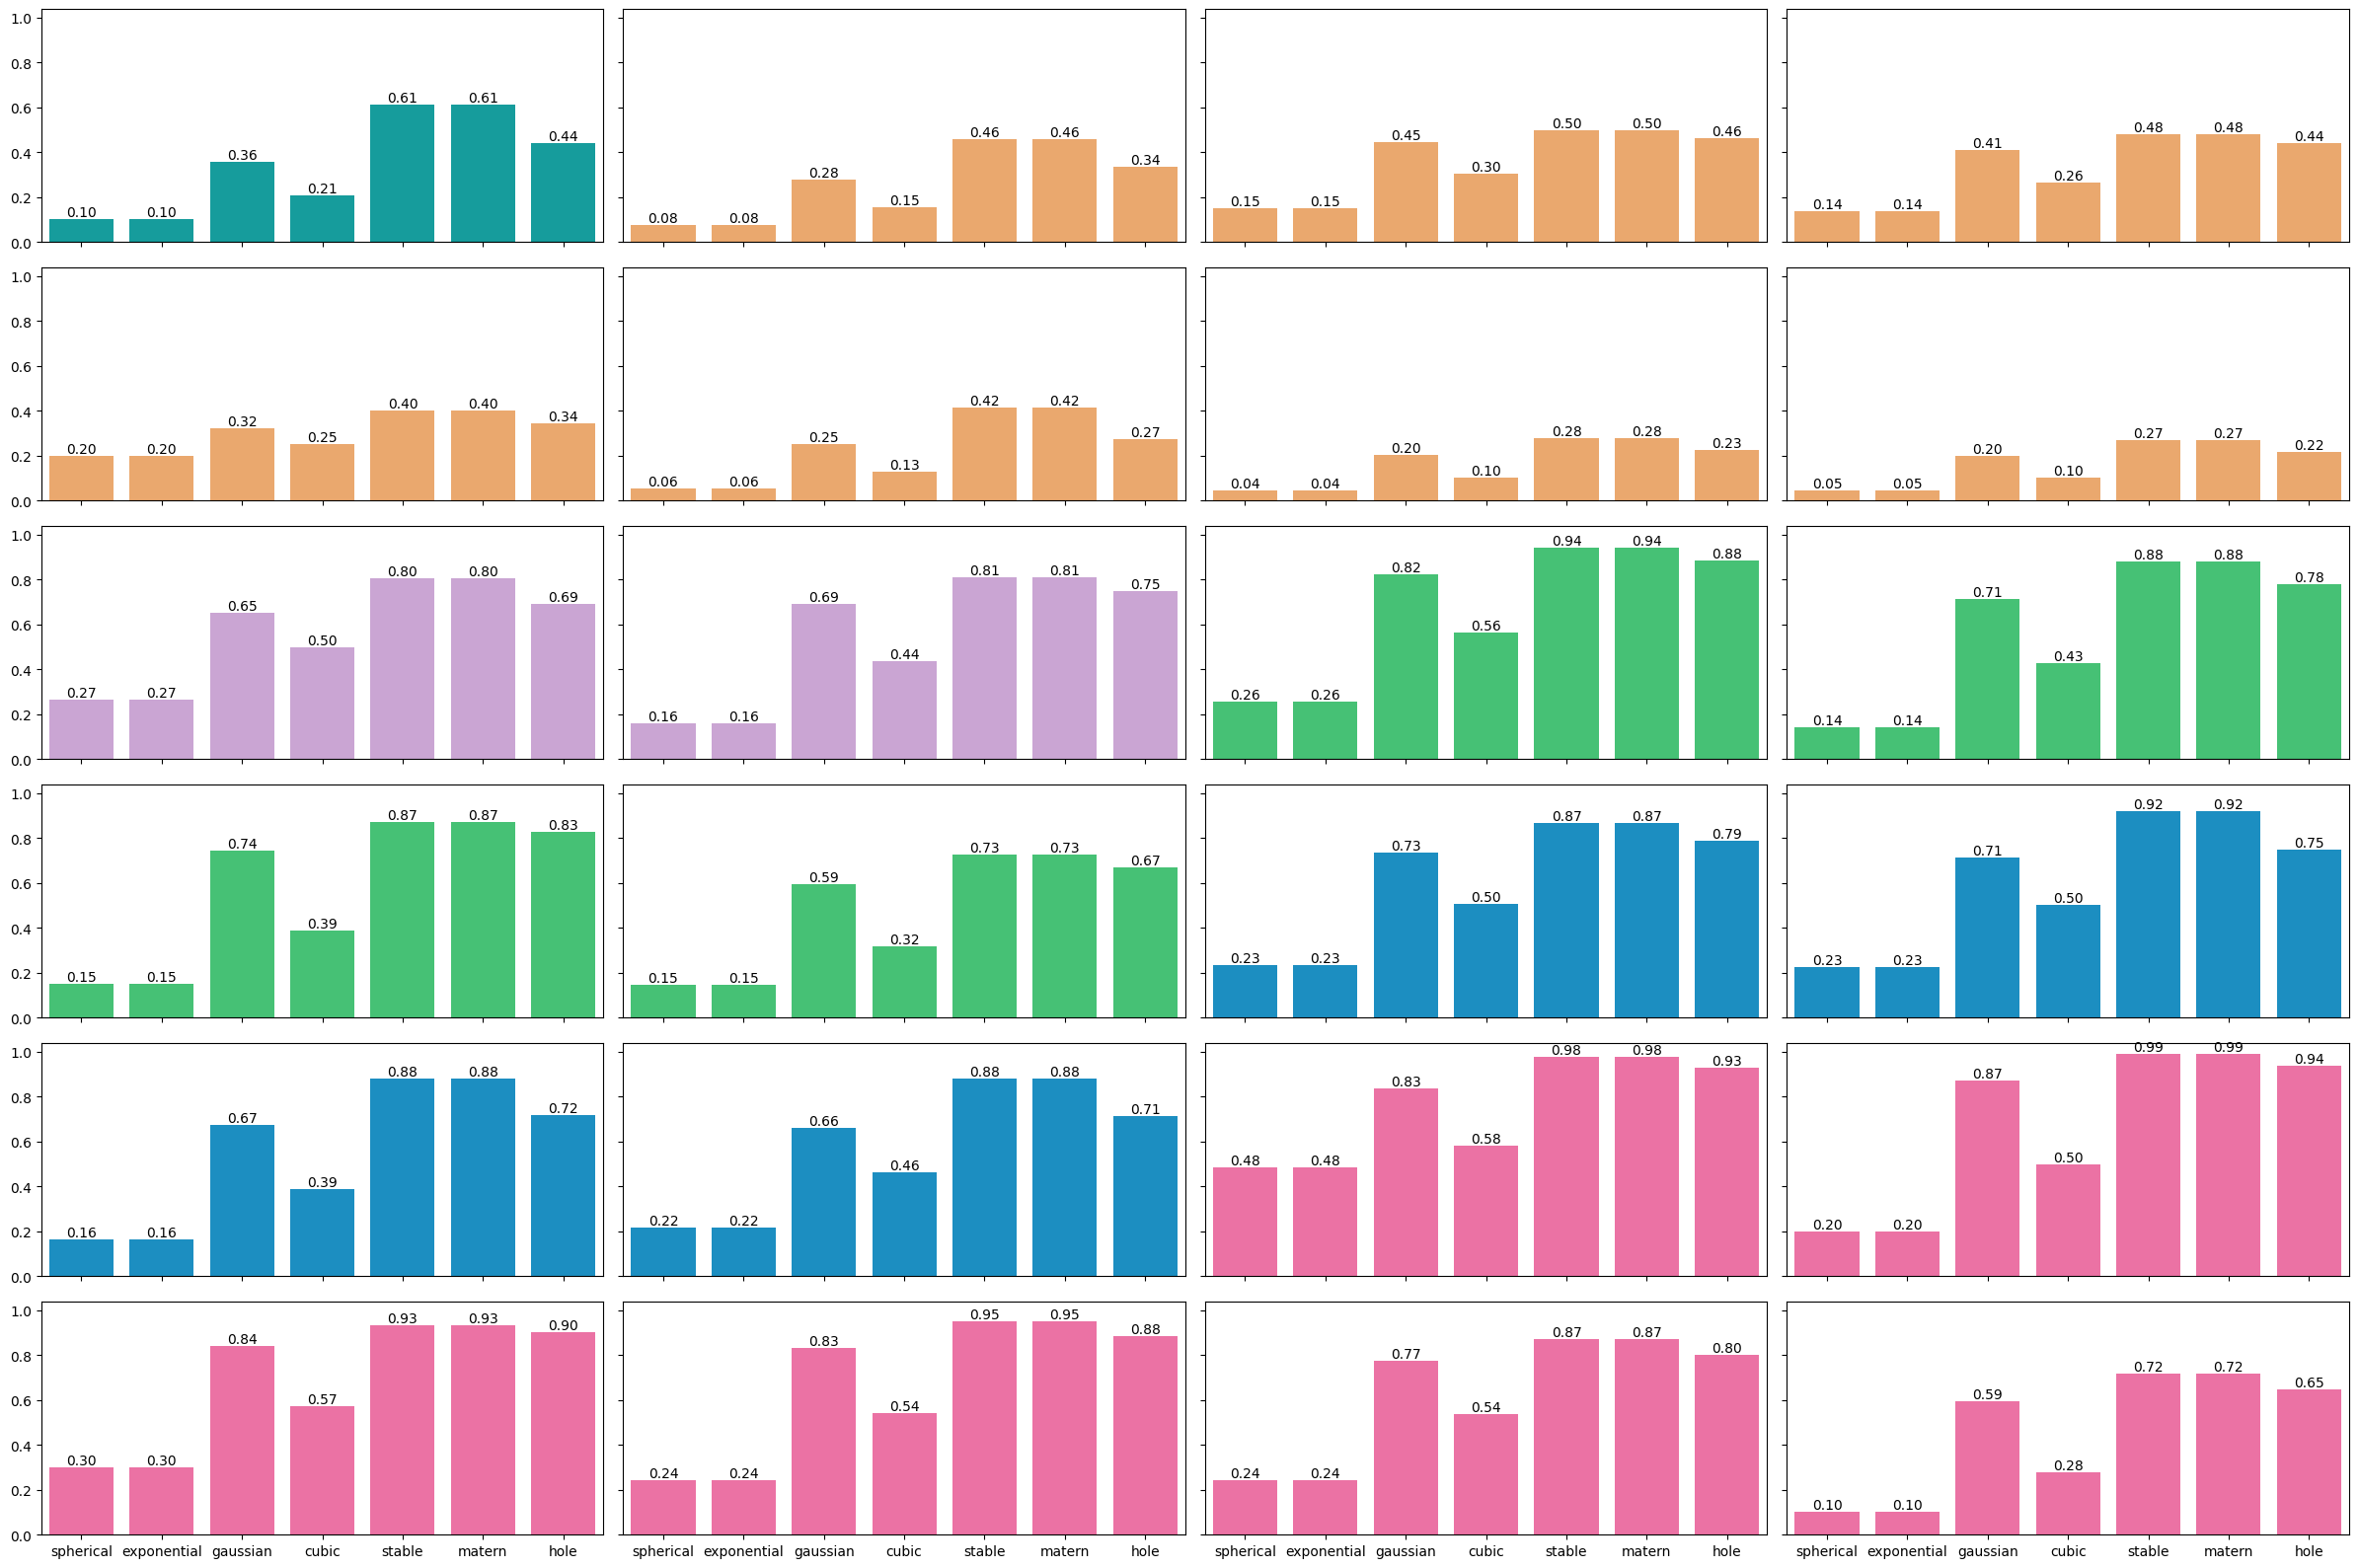

In [338]:
import seaborn as sns
import pandas as pd
fig, axs = plt.subplots(6, 4, figsize = (24, 16), sharey=True, sharex=True)

for mi, mapname in enumerate(mapnames):
    mapname=mapnames[mi]

    scores = pd.DataFrame(error[mapname], index = gstools_mdls.keys())

    row = mi // 4 ; col = mi % 4
    sns.barplot(scores, errorbar='se', color = extended_cpal[mapname], ax=axs[row, col])
    axs[row, col].bar_label(axs[row, col].containers[0], fmt='%.2f', fontsize=10)
plt.tight_layout()
plt.savefig(projdir + '/figs/rev_variogram_fit_50pct.svg')

In [404]:
scoreboard = None

for mapname in mapnames:
    if mapname == mapnames[0]: 
        scoreboard = pd.DataFrame([error[mapname]], index = [mapname])
    else:
        scoreboard = pd.concat([scoreboard, pd.DataFrame([error[mapname]], index = [mapname])])

In [405]:
scoreboard

,spherical,exponential,gaussian,cubic,stable,matern,hole
abagen_genepc1,0.190561,0.190413,0.422395,0.280074,0.636338,0.636339,0.491637
hcps1200_megbeta,0.145325,0.145115,0.322272,0.193346,0.466070,0.466071,0.371446
hcps1200_meggamma2,0.293500,0.293593,0.469662,0.368892,0.506897,0.506897,0.481303
hcps1200_meggamma1,0.253188,0.253155,0.432064,0.316756,0.481841,0.481841,0.454441
hcps1200_megtimescale,0.243219,0.242948,0.330065,0.270595,0.399412,0.399413,0.341210
hcps1200_megtheta,0.111817,0.112111,0.266545,0.170138,0.418841,0.418842,0.286513
hcps1200_megalpha,0.086801,0.087045,0.219146,0.136308,0.283765,0.283766,0.234483
hcps1200_megdelta,0.092921,0.093017,0.213173,0.137020,0.269511,0.269511,0.226016
hcps1200_thickness,0.486026,0.485703,0.704496,0.582570,0.833251,0.833252,0.733005
hcps1200_myelinmap,0.374970,0.375306,0.729745,0.560614,0.827272,0.827272,0.775559


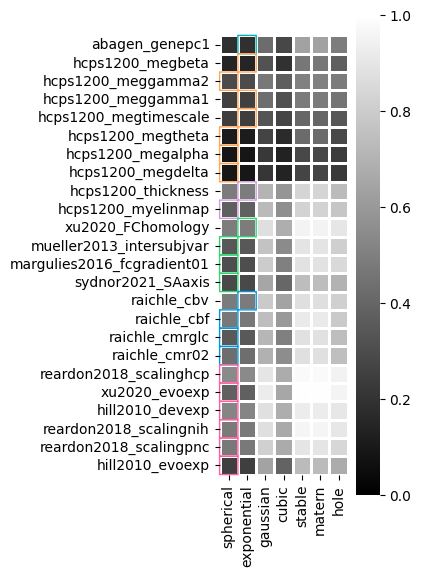

In [406]:
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize = (4,10))
sns.heatmap(scoreboard, square=True, cmap = 'gist_yarg_r', linecolor = 'w', linewidth = 1, vmin=0, vmax = 1, ax=ax)

data = scoreboard.T
row_labels = []

for mapname in mapnames:
    col_label = mapname
    row_label = data[mapname].sort_values(ascending = True).index[0]
    row_labels.append(row_label)


    j = data.index.get_loc(row_label)
    i = data.columns.get_loc(col_label)
    
    #ax.add_patch(
    #    plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="dimgray", linewidth=2)
    #)
    
    ax.add_patch(
        FancyBboxPatch(
            (j, i), 1, 1,
            boxstyle="round,pad=0.0001",
            linewidth=1,
            edgecolor=extended_cpal[mapname],
            facecolor="none", clip_on=False
        ))
    

plt.tight_layout()
plt.savefig(projdir + "/figs/rev_ok_neuromaps_pct10.svg")